**Data Loading, Cleaning and Validation**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("/content/restaurant_staffing_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Date,Outlet_ID,Hour,Order_Volume,Average_Preparation_Time,Queue_Length,Staff_Count,Day_Type,Holiday
0,2026-01-01,O001,7,33,5.65,0,2,Weekday,No
1,2026-01-01,O001,8,42,5.86,0,2,Weekday,No
2,2026-01-01,O001,9,48,5.81,0,3,Weekday,No
3,2026-01-01,O001,10,63,5.69,0,4,Weekday,No
4,2026-01-01,O001,11,86,8.45,11,3,Weekday,No


In [ ]:
df.shape

In [ ]:
df.columns

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      5000 non-null   object 
 1   Outlet_ID                 5000 non-null   object 
 2   Hour                      5000 non-null   int64  
 3   Order_Volume              5000 non-null   int64  
 4   Average_Preparation_Time  5000 non-null   float64
 5   Queue_Length              5000 non-null   int64  
 6   Staff_Count               5000 non-null   int64  
 7   Day_Type                  5000 non-null   object 
 8   Holiday                   5000 non-null   object 
dtypes: float64(1), int64(4), object(4)
memory usage: 351.7+ KB


In [7]:
df["Date"] = pd.to_datetime(df["Date"])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Date                      5000 non-null   datetime64[ns]
 1   Outlet_ID                 5000 non-null   object        
 2   Hour                      5000 non-null   int64         
 3   Order_Volume              5000 non-null   int64         
 4   Average_Preparation_Time  5000 non-null   float64       
 5   Queue_Length              5000 non-null   int64         
 6   Staff_Count               5000 non-null   int64         
 7   Day_Type                  5000 non-null   object        
 8   Holiday                   5000 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(4), object(3)
memory usage: 351.7+ KB


In [9]:
df.isnull().sum()

,0
Date,0
Outlet_ID,0
Hour,0
Order_Volume,0
Average_Preparation_Time,0
Queue_Length,0
Staff_Count,0
Day_Type,0
Holiday,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe()

,Date,Hour,Order_Volume,Average_Preparation_Time,Queue_Length,Staff_Count
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2026-01-16 00:09:30.240000,14.504400,76.391200,6.226182,1.862600,4.114000
min,2026-01-01 00:00:00,7.000000,9.000000,3.500000,0.000000,2.000000
25%,2026-01-08 00:00:00,11.000000,49.000000,5.530000,0.000000,3.000000
50%,2026-01-16 00:00:00,14.500000,71.000000,6.190000,0.000000,4.000000
75%,2026-01-24 00:00:00,19.000000,101.000000,6.862500,3.000000,5.000000
max,2026-01-31 00:00:00,22.000000,219.000000,11.130000,21.000000,11.000000
std,NaN,4.611099,34.821514,1.002537,3.316432,1.676057


In [13]:
print("Outlets:")
print(df["Outlet_ID"].unique())

print("\nDay Types:")
print(df["Day_Type"].unique())

print("\nHoliday:")
print(df["Holiday"].unique())

Outlets:
['O001' 'O002' 'O003' 'O004' 'O005' 'O006' 'O007' 'O008' 'O009' 'O010']

Day Types:
['Weekday' 'Weekend']

Holiday:
['No' 'Yes']


In [14]:
numeric_columns = [
    "Order_Volume",
    "Average_Preparation_Time",
    "Queue_Length",
    "Staff_Count"
]

for col in numeric_columns:
    print(col, "negative values:", (df[col] < 0).sum())

Order_Volume negative values: 0
Average_Preparation_Time negative values: 0
Queue_Length negative values: 0
Staff_Count negative values: 0


In [15]:
df["Staff_Count"].value_counts().sort_index()

,count
Staff_Count,
2,1040
3,927
4,1246
5,649
6,703
7,268
8,128
9,30
10,7


In [16]:
df["Order_Volume"].describe()

,Order_Volume
count,5000.000000
mean,76.391200
std,34.821514
min,9.000000
25%,49.000000
50%,71.000000
75%,101.000000
max,219.000000


In [17]:
print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())

Start date: 2026-01-01 00:00:00
End date: 2026-01-31 00:00:00


In [18]:
df["Outlet_ID"].value_counts().sort_index()

,count
Outlet_ID,
O001,497
O002,501
O003,502
O004,496
O005,503
O006,500
O007,500
O008,500
O009,502


In [ ]:
df["Day_Type"].value_counts()

In [20]:
df["Holiday"].value_counts()

,count
Holiday,
No,4352
Yes,648


## 2. Exploratory Data Analysis (EDA)

This section explores order demand, preparation time, queue length, staffing levels, and outlet-level patterns to understand the operational behavior of the restaurants.

In [21]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,5000,2026-01-16 00:09:30.240000,2026-01-01 00:00:00,2026-01-08 00:00:00,2026-01-16 00:00:00,2026-01-24 00:00:00,2026-01-31 00:00:00,NaN
Hour,5000.0,14.5044,7.0,11.0,14.5,19.0,22.0,4.611099
Order_Volume,5000.0,76.3912,9.0,49.0,71.0,101.0,219.0,34.821514
Average_Preparation_Time,5000.0,6.226182,3.5,5.53,6.19,6.8625,11.13,1.002537
Queue_Length,5000.0,1.8626,0.0,0.0,0.0,3.0,21.0,3.316432
Staff_Count,5000.0,4.114,2.0,3.0,4.0,5.0,11.0,1.676057


In [22]:
df[[
    "Order_Volume",
    "Average_Preparation_Time",
    "Queue_Length",
    "Staff_Count"
]].mean()

,0
Order_Volume,76.391200
Average_Preparation_Time,6.226182
Queue_Length,1.862600
Staff_Count,4.114000


In [23]:
hourly_demand = (
    df.groupby("Hour")["Order_Volume"]
      .mean()
      .reset_index()
)

hourly_demand

,Hour,Order_Volume
0,7,25.932692
1,8,34.781350
2,9,43.528846
3,10,56.426282
4,11,73.907643
5,12,104.694268
6,13,117.916399
7,14,95.754777
8,15,61.207668
9,16,52.248408


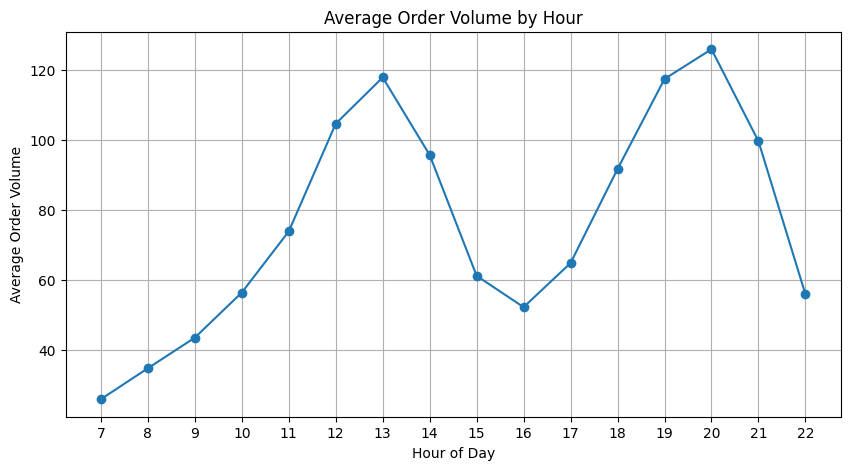

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_demand["Hour"],
    hourly_demand["Order_Volume"],
    marker="o"
)

plt.title("Average Order Volume by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Order Volume")
plt.xticks(range(7, 23))
plt.grid(True)

plt.show()

In [25]:
df["Orders_Per_Employee"] = (
    df["Order_Volume"] / df["Staff_Count"]
)

df[[
    "Order_Volume",
    "Staff_Count",
    "Orders_Per_Employee"
]].head(10)

,Order_Volume,Staff_Count,Orders_Per_Employee
0,33,2,16.500000
1,42,2,21.000000
2,48,3,16.000000
3,63,4,15.750000
4,86,3,28.666667
5,110,5,22.000000
6,121,6,20.166667
7,94,5,18.800000
8,66,3,22.000000
9,55,3,18.333333


In [26]:
df["Orders_Per_Employee"].describe()

,Orders_Per_Employee
count,5000.000000
mean,18.476414
std,3.910981
min,4.500000
25%,16.200000
50%,18.800000
75%,20.750000
max,33.000000


In [27]:
staffing_benchmark = df["Orders_Per_Employee"].quantile(0.75)

print("Staffing benchmark:",
      round(staffing_benchmark, 2),
      "orders per employee")

Staffing benchmark: 20.75 orders per employee


In [28]:
import numpy as np

df["Recommended_Staff"] = np.ceil(
    df["Order_Volume"] / staffing_benchmark
).astype(int)

df[[
    "Order_Volume",
    "Staff_Count",
    "Orders_Per_Employee",
    "Recommended_Staff"
]].head(15)

,Order_Volume,Staff_Count,Orders_Per_Employee,Recommended_Staff
0,33,2,16.500000,2
1,42,2,21.000000,3
2,48,3,16.000000,3
3,63,4,15.750000,4
4,86,3,28.666667,5
5,110,5,22.000000,6
6,121,6,20.166667,6
7,94,5,18.800000,5
8,66,3,22.000000,4
9,55,3,18.333333,3


In [29]:
def classify_staffing(row):
    if row["Staff_Count"] < row["Recommended_Staff"]:
        return "Understaffed"
    elif row["Staff_Count"] > row["Recommended_Staff"]:
        return "Overstaffed"
    else:
        return "Adequately Staffed"

df["Staffing_Status"] = df.apply(classify_staffing, axis=1)

df["Staffing_Status"].value_counts()

,count
Staffing_Status,
Adequately Staffed,2857
Understaffed,1229
Overstaffed,914


In [30]:
staffing_distribution = (
    df["Staffing_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

staffing_distribution

,proportion
Staffing_Status,
Adequately Staffed,57.14
Understaffed,24.58
Overstaffed,18.28


In [31]:
understaffed = df[
    df["Staffing_Status"] == "Understaffed"
].copy()

understaffed["Staff_Shortage"] = (
    understaffed["Recommended_Staff"]
    - understaffed["Staff_Count"]
)

understaffed.sort_values(
    "Staff_Shortage",
    ascending=False
)[[
    "Date",
    "Outlet_ID",
    "Hour",
    "Order_Volume",
    "Staff_Count",
    "Recommended_Staff",
    "Queue_Length",
    "Staff_Shortage"
]].head(15)

,Date,Outlet_ID,Hour,Order_Volume,Staff_Count,Recommended_Staff,Queue_Length,Staff_Shortage
4053,2026-01-26,O002,12,104,4,6,7,2
3020,2026-01-19,O008,11,85,3,5,9,2
493,2026-01-04,O001,19,127,5,7,12,2
4054,2026-01-26,O002,13,130,5,7,13,2
4058,2026-01-26,O002,17,66,2,4,18,2
1846,2026-01-12,O005,14,86,3,5,16,2
2263,2026-01-15,O001,13,167,7,9,17,2
3632,2026-01-23,O006,11,84,3,5,11,2
3038,2026-01-19,O009,13,85,3,5,9,2
550,2026-01-04,O005,12,87,3,5,10,2


In [32]:
overstaffed = df[
    df["Staffing_Status"] == "Overstaffed"
].copy()

overstaffed["Extra_Staff"] = (
    overstaffed["Staff_Count"]
    - overstaffed["Recommended_Staff"]
)

overstaffed.sort_values(
    "Extra_Staff",
    ascending=False
)[[
    "Date",
    "Outlet_ID",
    "Hour",
    "Order_Volume",
    "Staff_Count",
    "Recommended_Staff",
    "Extra_Staff"
]].head(15)

,Date,Outlet_ID,Hour,Order_Volume,Staff_Count,Recommended_Staff,Extra_Staff
1511,2026-01-10,O004,19,92,8,5,3
3931,2026-01-25,O004,19,90,8,5,3
4253,2026-01-27,O004,18,75,6,4,2
1885,2026-01-12,O007,21,81,6,4,2
700,2026-01-05,O004,16,39,4,2,2
4248,2026-01-27,O004,13,82,6,4,2
745,2026-01-05,O007,13,72,6,4,2
3116,2026-01-20,O004,10,37,4,2,2
3118,2026-01-20,O004,12,71,6,4,2
4082,2026-01-26,O004,9,37,4,2,2


In [33]:
staffing_by_hour = (
    df.groupby("Hour")
      .agg(
          Average_Orders=("Order_Volume", "mean"),
          Average_Staff=("Staff_Count", "mean"),
          Recommended_Staff=("Recommended_Staff", "mean"),
          Average_Queue=("Queue_Length", "mean"),
          Orders_Per_Employee=("Orders_Per_Employee", "mean")
      )
      .reset_index()
)

staffing_by_hour

,Hour,Average_Orders,Average_Staff,Recommended_Staff,Average_Queue,Orders_Per_Employee
0,7,25.932692,2.105769,1.814103,0.355769,12.438301
1,8,34.781350,2.202572,2.167203,0.463023,16.013934
2,9,43.528846,2.551282,2.560897,0.750000,17.509081
3,10,56.426282,3.160256,3.233974,1.358974,18.611859
4,11,73.907643,3.961783,4.060510,1.882166,19.193123
5,12,104.694268,5.417197,5.535032,2.222930,19.641572
6,13,117.916399,6.109325,6.167203,2.575563,19.549490
7,14,95.754777,4.914013,5.101911,2.563694,19.706974
8,15,61.207668,3.444089,3.472843,1.840256,18.400213
9,16,52.248408,2.942675,3.028662,1.888535,18.501008


In [34]:
staffing_by_hour["Recommended_Staff"] = (
    staffing_by_hour["Recommended_Staff"]
    .round()
    .astype(int)
)

staffing_by_hour.round(2)

,Hour,Average_Orders,Average_Staff,Recommended_Staff,Average_Queue,Orders_Per_Employee
0,7,25.93,2.11,2,0.36,12.44
1,8,34.78,2.20,2,0.46,16.01
2,9,43.53,2.55,3,0.75,17.51
3,10,56.43,3.16,3,1.36,18.61
4,11,73.91,3.96,4,1.88,19.19
5,12,104.69,5.42,6,2.22,19.64
6,13,117.92,6.11,6,2.58,19.55
7,14,95.75,4.91,5,2.56,19.71
8,15,61.21,3.44,3,1.84,18.40
9,16,52.25,2.94,3,1.89,18.50


In [35]:
staff_queue_corr = df[
    ["Staff_Count", "Queue_Length"]
].corr()

staff_queue_corr

,Staff_Count,Queue_Length
Staff_Count,1.000000,0.036143
Queue_Length,0.036143,1.000000


In [36]:
queue_by_staff = (
    df.groupby("Staff_Count")["Queue_Length"]
      .mean()
      .reset_index()
)

queue_by_staff

,Staff_Count,Queue_Length
0,2,1.672115
1,3,1.889968
2,4,1.677368
3,5,2.377504
4,6,1.763869
5,7,2.287313
6,8,2.023438
7,9,2.133333
8,10,1.857143
9,11,0.000000


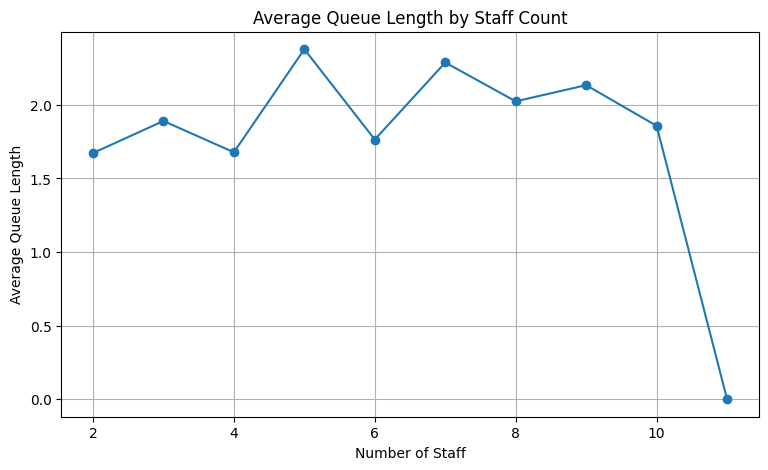

In [37]:
plt.figure(figsize=(9,5))

plt.plot(
    queue_by_staff["Staff_Count"],
    queue_by_staff["Queue_Length"],
    marker="o"
)

plt.title("Average Queue Length by Staff Count")
plt.xlabel("Number of Staff")
plt.ylabel("Average Queue Length")
plt.grid(True)

plt.show()

In [38]:
outlet_analysis = (
    df.groupby("Outlet_ID")
      .agg(
          Average_Orders=("Order_Volume", "mean"),
          Average_Staff=("Staff_Count", "mean"),
          Average_Queue=("Queue_Length", "mean"),
          Average_Prep_Time=("Average_Preparation_Time", "mean"),
          Average_Orders_Per_Employee=("Orders_Per_Employee", "mean"),
          Understaffed_Percent=(
              "Staffing_Status",
              lambda x: (x == "Understaffed").mean() * 100
          )
      )
      .reset_index()
)

outlet_analysis.round(2)

,Outlet_ID,Average_Orders,Average_Staff,Average_Queue,Average_Prep_Time,Average_Orders_Per_Employee,Understaffed_Percent
0,O001,88.93,4.56,2.64,6.13,19.46,33.20
1,O002,73.93,3.93,1.79,6.23,18.72,24.35
2,O003,85.19,4.40,2.47,6.82,19.35,29.68
3,O004,59.61,3.77,0.62,5.40,16.01,13.10
4,O005,70.40,3.80,1.69,6.23,18.39,20.87
5,O006,81.43,4.24,2.03,6.17,19.12,27.00
6,O007,65.34,3.99,0.78,6.36,16.45,14.60
7,O008,92.59,4.72,2.36,6.65,19.59,30.20
8,O009,68.27,3.63,1.79,5.94,18.65,26.69
9,O010,78.21,4.10,2.46,6.32,19.01,26.05


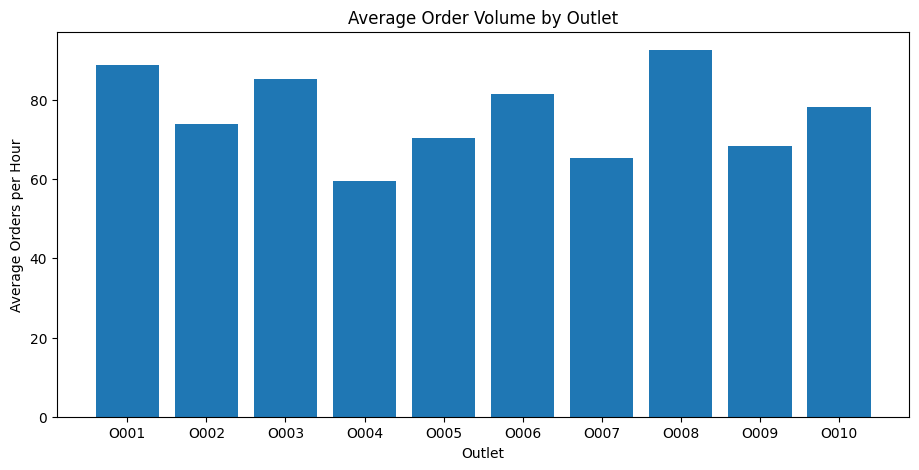

In [39]:
plt.figure(figsize=(11,5))

plt.bar(
    outlet_analysis["Outlet_ID"],
    outlet_analysis["Average_Orders"]
)

plt.title("Average Order Volume by Outlet")
plt.xlabel("Outlet")
plt.ylabel("Average Orders per Hour")

plt.show()

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_data = df[
    [
        "Hour",
        "Outlet_ID",
        "Day_Type",
        "Holiday",
        "Order_Volume"
    ]
].copy()

model_data = pd.get_dummies(
    model_data,
    columns=["Outlet_ID", "Day_Type", "Holiday"],
    drop_first=True
)

X = model_data.drop("Order_Volume", axis=1)
y = model_data["Order_Volume"]

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4000
Testing samples: 1000


In [42]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=None,
    min_samples_split=2,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [43]:
y_pred = rf_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,40,34.299332
1,126,131.409818
2,57,63.444092
3,77,63.213962
4,61,70.685015
5,58,49.733077
6,104,113.087970
7,34,22.183206
8,67,64.728613
9,116,114.799420


In [44]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-----------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 3))

Model Evaluation
-----------------
MAE : 7.31
RMSE: 9.97
R²  : 0.917


In [45]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
0,Hour,0.809638
11,Holiday_Yes,0.055771
3,Outlet_ID_O004,0.029843
10,Day_Type_Weekend,0.022257
7,Outlet_ID_O008,0.021815
6,Outlet_ID_O007,0.017631
8,Outlet_ID_O009,0.012320
4,Outlet_ID_O005,0.010467
1,Outlet_ID_O002,0.006936
2,Outlet_ID_O003,0.005023


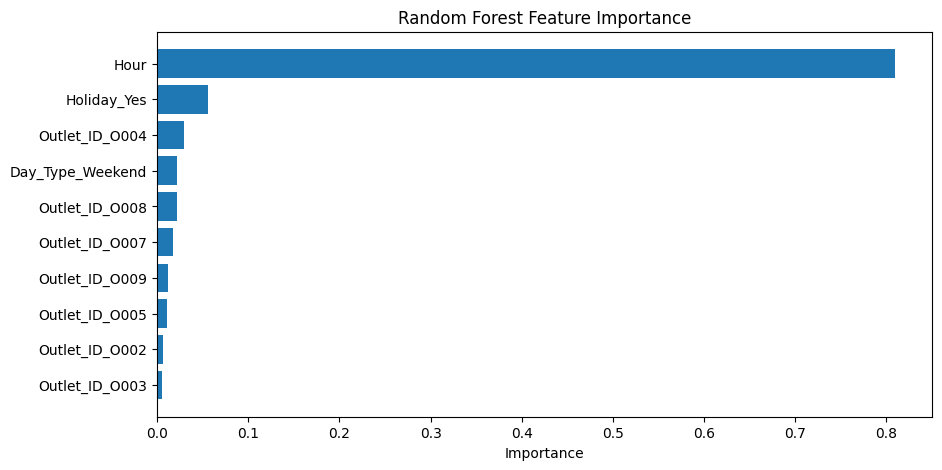

In [46]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10,5))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")

plt.show()

In [47]:
final_staffing_plan = staffing_by_hour[
    [
        "Hour",
        "Average_Orders",
        "Average_Staff",
        "Recommended_Staff",
        "Average_Queue",
        "Orders_Per_Employee"
    ]
].copy()

final_staffing_plan

,Hour,Average_Orders,Average_Staff,Recommended_Staff,Average_Queue,Orders_Per_Employee
0,7,25.932692,2.105769,2,0.355769,12.438301
1,8,34.781350,2.202572,2,0.463023,16.013934
2,9,43.528846,2.551282,3,0.750000,17.509081
3,10,56.426282,3.160256,3,1.358974,18.611859
4,11,73.907643,3.961783,4,1.882166,19.193123
5,12,104.694268,5.417197,6,2.222930,19.641572
6,13,117.916399,6.109325,6,2.575563,19.549490
7,14,95.754777,4.914013,5,2.563694,19.706974
8,15,61.207668,3.444089,3,1.840256,18.400213
9,16,52.248408,2.942675,3,1.888535,18.501008


In [48]:
final_staffing_plan.round(2)

,Hour,Average_Orders,Average_Staff,Recommended_Staff,Average_Queue,Orders_Per_Employee
0,7,25.93,2.11,2,0.36,12.44
1,8,34.78,2.20,2,0.46,16.01
2,9,43.53,2.55,3,0.75,17.51
3,10,56.43,3.16,3,1.36,18.61
4,11,73.91,3.96,4,1.88,19.19
5,12,104.69,5.42,6,2.22,19.64
6,13,117.92,6.11,6,2.58,19.55
7,14,95.75,4.91,5,2.56,19.71
8,15,61.21,3.44,3,1.84,18.40
9,16,52.25,2.94,3,1.89,18.50


In [49]:
peak_hours = (
    hourly_demand
    .sort_values("Order_Volume", ascending=False)
    .head(5)
)

peak_hours

,Hour,Order_Volume
13,20,125.980831
6,13,117.916399
12,19,117.482315
5,12,104.694268
14,21,99.679365


In [50]:
problem_hours = (
    df[df["Staffing_Status"] == "Understaffed"]
    .groupby("Hour")
    .size()
    .reset_index(name="Understaffed_Records")
    .sort_values("Understaffed_Records", ascending=False)
)

problem_hours

,Hour,Understaffed_Records
14,21,109
5,12,106
6,13,99
13,20,96
7,14,93
12,19,91
4,11,86
9,16,84
11,18,82
3,10,81


In [51]:
print("=== KEY DATA POINTS ===")

print(
    "\nHighest demand hour:",
    int(hourly_demand.loc[
        hourly_demand["Order_Volume"].idxmax(), "Hour"
    ])
)

print(
    "Highest average orders:",
    round(hourly_demand["Order_Volume"].max(), 2)
)

print(
    "\nAverage orders per employee:",
    round(df["Orders_Per_Employee"].mean(), 2)
)

print(
    "\nAverage queue length:",
    round(df["Queue_Length"].mean(), 2)
)

print(
    "\nUnderstaffed records:",
    (df["Staffing_Status"] == "Understaffed").sum()
)

print(
    "Adequately staffed records:",
    (df["Staffing_Status"] == "Adequately Staffed").sum()
)

print(
    "Overstaffed records:",
    (df["Staffing_Status"] == "Overstaffed").sum()
)

print(
    "\nStaff vs Queue correlation:",
    round(
        df["Staff_Count"].corr(df["Queue_Length"]),
        3
    )
)

print(
    "\nBest average outlet by order volume:"
)

print(
    outlet_analysis.loc[
        outlet_analysis["Average_Orders"].idxmax()
    ]
)

=== KEY DATA POINTS ===

Highest demand hour: 20
Highest average orders: 125.98

Average orders per employee: 18.48

Average queue length: 1.86

Understaffed records: 1229
Adequately staffed records: 2857
Overstaffed records: 914

Staff vs Queue correlation: 0.036

Best average outlet by order volume:
Outlet_ID                          O008
Average_Orders                   92.586
Average_Staff                     4.724
Average_Queue                      2.36
Average_Prep_Time               6.64728
Average_Orders_Per_Employee    19.58838
Understaffed_Percent               30.2
Name: 7, dtype: object


In [52]:
df.to_csv(
    "restaurant_staffing_analysis.csv",
    index=False
)

print("Final analysis dataset saved.")

Final analysis dataset saved.
